# Credit Score Classification — Exploratory Data Analysis

Goal: understand a messy, real-world-style credit dataset (25,000 customer records, 3 classes: **Good / Standard / Poor**) and decide how to clean and preprocess it before modelling.

In [1]:
# ========================================
# 1. IMPORT LIBRARIES
# ========================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Load & First Look

Load the raw data and inspect it. Many numeric columns are stored as strings because they contain stray characters.

In [2]:
# ========================================
# 2. LOAD DATA
# ========================================
df_raw = pd.read_csv('../data/credit_score_data.csv', index_col=0)

print(f"Shape: {df_raw.shape}")
print(f"\nTarget distribution:")
print(df_raw['Credit_Score'].value_counts())
print(f"\nProportion:")
print(df_raw['Credit_Score'].value_counts(normalize=True).round(3))

Shape: (25000, 28)

Target distribution:
Credit_Score
Standard    13330
Poor         7302
Good         4368
Name: count, dtype: int64

Proportion:
Credit_Score
Standard    0.533
Poor        0.292
Good        0.175
Name: proportion, dtype: float64


In [3]:
# First 5 rows
df_raw.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0xa658,CUS_0x936d,March,Alistair Barrs,8466,703-48-3482,_______,100433.58,8074.465000,1,...,Good,1023.93,33.471395,20 Years and 5 Months,No,100.163466,758.0704866746678,Low_spent_Medium_value_payments,229.21254743638283,Standard
1,0x6739,CUS_0x9a29,August,Phila,25,339-28-0072,Developer,33119.82,3024.985000,10,...,Bad,2545.0,33.810567,14 Years and 8 Months,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.6074980582689,Poor
2,0xdcf5,CUS_0x12a9,April,Driverb,44,583-20-9758,_______,44822.21,3555.184167,1,...,Good,730.64,31.145739,23 Years and 10 Months,NM,135.044286,256.4742969677053,Low_spent_Medium_value_payments,243.99983412342044,Standard
3,0x14453,CUS_0x3bad,June,Prasadc,29,510-25-2095,Musician,142081.48,11771.123333,6,...,Standard,932.32,28.409526,27 Years and 0 Months,No,180.616478,423.96126196668365,Low_spent_Small_value_payments,862.534593039876,Standard
4,0x1198e,CUS_0xa3e1,January,Poornimai,45,943-92-4350,Scientist,19267.27_,1374.605833,10,...,Bad,3777.55,28.373426,10 Years and 3 Months,Yes,78.954825,133.56850235207634,Low_spent_Small_value_payments,214.93725572483646,Poor


In [4]:
# Data types — note how many numeric columns are 'object' (string)
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        25000 non-null  str    
 1   Customer_ID               25000 non-null  str    
 2   Month                     25000 non-null  str    
 3   Name                      22440 non-null  str    
 4   Age                       25000 non-null  str    
 5   SSN                       25000 non-null  str    
 6   Occupation                25000 non-null  str    
 7   Annual_Income             25000 non-null  str    
 8   Monthly_Inhand_Salary     21417 non-null  float64
 9   Num_Bank_Accounts         25000 non-null  int64  
 10  Num_Credit_Card           25000 non-null  int64  
 11  Interest_Rate             25000 non-null  int64  
 12  Num_of_Loan               25000 non-null  str    
 13  Type_of_Loan              22172 non-null  str    
 14  Delay_from_due_da

In [5]:
# Examples of dirty values: trailing underscores & placeholders
print("Sample Age values (should be int):")
print(df_raw['Age'].head(10).tolist())
print("\nSample Annual_Income values (should be float):")
print(df_raw['Annual_Income'].head(5).tolist())
print("\nOccupation values (note the \'_______\' placeholder):")
print(df_raw['Occupation'].value_counts().head(8))
print("\nSample Credit_History_Age values (stored as text):")
print(df_raw['Credit_History_Age'].head(5).tolist())

Sample Age values (should be int):
['8466', '25', '44', '29', '45', '49', '18', '51', '27', '39_']

Sample Annual_Income values (should be float):
['100433.58', '33119.82', '44822.21', '142081.48', '19267.27_']

Occupation values (note the '_______' placeholder):
Occupation
_______          1770
Engineer         1650
Lawyer           1618
Architect        1613
Media_Manager    1575
Accountant       1569
Entrepreneur     1559
Developer        1556
Name: count, dtype: int64

Sample Credit_History_Age values (stored as text):
['20 Years and 5 Months', '14 Years and 8 Months', '23 Years and 10 Months', '27 Years and 0 Months', '10 Years and 3 Months']


## 3. Missing Values (Before Cleaning)

Missing-value patterns drive the imputation strategy, so we look at them **before** imputing.
Note that much of the "missing" data is still **hidden** behind junk placeholders
(`_______`, `_`, `!@9#%8`) and only shows up as NaN after cleaning.

In [6]:
# ========================================
# 3. MISSING VALUES (RAW)
# ========================================
missing_raw = df_raw.isnull().sum()
missing_raw = missing_raw[missing_raw > 0].sort_values(ascending=False)
print("Missing values (raw, before cleaning):")
print(missing_raw if len(missing_raw) > 0 else "No explicit NaN (but hidden placeholders exist)")

Missing values (raw, before cleaning):
Monthly_Inhand_Salary      3583
Type_of_Loan               2828
Name                       2560
Credit_History_Age         2249
Num_of_Delayed_Payment     1733
Amount_invested_monthly    1164
Num_Credit_Inquiries        506
Monthly_Balance             289
dtype: int64


## 4. Data Cleaning
- Trailing underscores: `'39_'` → `39`
- Junk placeholders: `_______`, `_`, `!@9#%8` → NaN
- Text durations: `'20 Years and 5 Months'` → `245` (months)
- Impossible ages (e.g. `8466`) → NaN, then imputed

In [7]:
# ========================================
# 4. DATA CLEANER CLASS
# ========================================
class DataCleaner:
    """All data cleaning steps, chainable (fluent interface)."""

    ID_COLS = ['ID', 'Customer_ID', 'Name', 'SSN']
    DROP_COLS = ['Type_of_Loan', 'Month']

    STRING_NUMERIC_COLS = [
        'Age', 'Annual_Income', 'Num_of_Loan',
        'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
        'Outstanding_Debt', 'Amount_invested_monthly',
        'Monthly_Balance'
    ]

    DIRTY_PLACEHOLDERS = {
        'Occupation': '_______',
        'Credit_Mix': '_',
        'Payment_Behaviour': '!@9#%8',
    }

    AGE_MIN = 14
    AGE_MAX = 100

    def __init__(self, df):
        self.df = df.copy()
        self.df_before_age_fix = None  # kept for the before/after plot

    @staticmethod
    def _clean_trailing_underscore(val):
        if isinstance(val, str):
            return val.rstrip('_').strip()
        return val

    @staticmethod
    def _parse_credit_history(val):
        if pd.isna(val):
            return np.nan
        match = re.match(r'(\d+)\s+Years?\s+and\s+(\d+)\s+Months?', str(val))
        if match:
            return int(match.group(1)) * 12 + int(match.group(2))
        return np.nan

    def drop_identity_cols(self):
        self.df = self.df.drop(columns=self.ID_COLS, errors='ignore')
        return self

    def clean_numeric_strings(self):
        for col in self.STRING_NUMERIC_COLS:
            self.df[col] = self.df[col].apply(self._clean_trailing_underscore)
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        return self

    def replace_placeholders(self):
        for col, placeholder in self.DIRTY_PLACEHOLDERS.items():
            self.df[col] = self.df[col].replace(placeholder, np.nan)
        return self

    def parse_credit_history(self):
        self.df['Credit_History_Age_Months'] = (
            self.df['Credit_History_Age'].apply(self._parse_credit_history)
        )
        self.df = self.df.drop(columns=['Credit_History_Age'])
        return self

    def handle_age_outliers(self):
        # Snapshot of Age before fixing (for the before/after plot)
        self.df_before_age_fix = self.df['Age'].copy()
        invalid = ((self.df['Age'] < self.AGE_MIN) | (self.df['Age'] > self.AGE_MAX)).sum()
        self.df.loc[
            (self.df['Age'] < self.AGE_MIN) | (self.df['Age'] > self.AGE_MAX),
            'Age'
        ] = np.nan
        print(f"Age outliers handled: {invalid} rows -> NaN")
        return self

    def drop_low_value_cols(self):
        self.df = self.df.drop(columns=self.DROP_COLS, errors='ignore')
        return self

    def impute_missing(self):
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()
        categorical_cols = self.df.select_dtypes(include=['object']).columns.tolist()
        if 'Credit_Score' in categorical_cols:
            categorical_cols.remove('Credit_Score')

        for col in numeric_cols:
            self.df[col] = self.df[col].fillna(self.df[col].median())
        for col in categorical_cols:
            self.df[col] = self.df[col].fillna(self.df[col].mode()[0])
        return self

    def drop_duplicates(self):
        before = len(self.df)
        self.df = self.df.drop_duplicates().reset_index(drop=True)
        print(f"Duplicates removed: {before - len(self.df)} rows")
        return self

    def run_until_placeholders(self):
        """Clean up to the point where placeholders become NaN, but BEFORE imputation.
        Useful for analysing missing values and outliers."""
        return (self
                .drop_identity_cols()
                .clean_numeric_strings()
                .replace_placeholders()
                .parse_credit_history()
                .drop_low_value_cols())

    def run_all(self):
        """Full cleaning including outlier handling, imputation and de-duplication."""
        return (self
                .drop_identity_cols()
                .clean_numeric_strings()
                .replace_placeholders()
                .parse_credit_history()
                .drop_low_value_cols()
                .handle_age_outliers()
                .impute_missing()
                .drop_duplicates()
                .df)

In [8]:
# Partial cleaning for analysis: placeholders -> NaN, before imputation
cleaner_partial = DataCleaner(df_raw)
df_pre_impute = cleaner_partial.run_until_placeholders().df

print("After placeholder cleaning (before imputation):")
print(f"Shape: {df_pre_impute.shape}")
print(f"\nMissing values now visible:")
missing_after_clean = df_pre_impute.isnull().sum()
print(missing_after_clean[missing_after_clean > 0].sort_values(ascending=False))

After placeholder cleaning (before imputation):
Shape: (25000, 22)

Missing values now visible:
Credit_Mix                   5066
Monthly_Inhand_Salary        3583
Credit_History_Age_Months    2249
Amount_invested_monthly      2199
Payment_Behaviour            1852
Occupation                   1770
Num_of_Delayed_Payment       1733
Changed_Credit_Limit          518
Num_Credit_Inquiries          506
Monthly_Balance               293
dtype: int64


## 5. Visualisation

In [9]:

class EDAExplorer:
    """All EDA plots in one place."""

    TARGET_COLORS = {'Good': 'green', 'Standard': 'orange', 'Poor': 'red'}
    CLASS_ORDER = ['Poor', 'Standard', 'Good']

    def __init__(self, df, target_col='Credit_Score'):
        self.df = df
        self.target_col = target_col
        self.numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        self.categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
        if target_col in self.categorical_cols:
            self.categorical_cols.remove(target_col)

    # ---- 5.1 Target distribution ----
    def plot_target_distribution(self):
        plt.figure(figsize=(8, 5))
        counts = self.df[self.target_col].value_counts()
        colors = [self.TARGET_COLORS[c] for c in counts.index]
        plt.bar(counts.index, counts.values, color=colors)
        plt.title('Credit Score Distribution', fontsize=14, fontweight='bold')
        plt.ylabel('Count')
        for i, v in enumerate(counts.values):
            plt.text(i, v + 100, str(v), ha='center', fontweight='bold')
        plt.tight_layout()
        plt.show()

    # ---- 5.2 Numeric distributions ----
    def plot_numeric_distributions(self, features):
        n = len(features)
        n_cols = 4
        n_rows = (n + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.5 * n_rows))
        axes = axes.ravel()
        for idx, feature in enumerate(features):
            axes[idx].hist(self.df[feature].dropna(), bins=30, color='skyblue', edgecolor='black')
            axes[idx].set_title(feature, fontweight='bold')
        for i in range(len(features), len(axes)):
            axes[i].axis('off')
        plt.tight_layout()
        plt.show()

    # ---- 5.3 Missing values heatmap ----
    def plot_missing_heatmap(self):
        plt.figure(figsize=(14, 6))
        sns.heatmap(self.df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
        plt.title('Missing Values Heatmap (yellow = missing)', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

        # Bar chart of missing values per column
        missing = self.df.isnull().sum()
        missing = missing[missing > 0].sort_values(ascending=False)
        if len(missing) > 0:
            plt.figure(figsize=(12, 5))
            missing.plot(kind='bar', color='salmon')
            plt.title('Missing Values per Column', fontweight='bold')
            plt.ylabel('Count')
            plt.tight_layout()
            plt.show()

    # ---- 5.4 Outlier detection (boxplots) ----
    def plot_outlier_boxplots(self, features):
        n = len(features)
        n_cols = 4
        n_rows = (n + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
        axes = axes.ravel()
        for idx, feature in enumerate(features):
            axes[idx].boxplot(self.df[feature].dropna(), vert=True)
            axes[idx].set_title(feature, fontweight='bold')
        for i in range(len(features), len(axes)):
            axes[i].axis('off')
        plt.suptitle('Outlier Detection (Boxplots)', fontsize=16, fontweight='bold', y=1.00)
        plt.tight_layout()
        plt.show()

    # ---- 5.5 Skewness check ----
    def plot_skewness(self, features):
        skew_vals = self.df[features].skew().sort_values(ascending=False)
        plt.figure(figsize=(12, 6))
        colors = ['red' if abs(s) > 1 else 'orange' if abs(s) > 0.5 else 'green'
                  for s in skew_vals.values]
        skew_vals.plot(kind='bar', color=colors)
        plt.axhline(y=1, color='red', linestyle='--', alpha=0.5, label='|skew|=1 (high)')
        plt.axhline(y=-1, color='red', linestyle='--', alpha=0.5)
        plt.axhline(y=0.5, color='orange', linestyle='--', alpha=0.5, label='|skew|=0.5 (moderate)')
        plt.axhline(y=-0.5, color='orange', linestyle='--', alpha=0.5)
        plt.title('Skewness per Numeric Feature', fontweight='bold')
        plt.ylabel('Skewness')
        plt.legend()
        plt.tight_layout()
        plt.show()
        return skew_vals

    # ---- 5.6 Correlation matrix ----
    def plot_correlation_matrix(self):
        plt.figure(figsize=(14, 10))
        correlation = self.df[self.numeric_cols].corr()
        sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm',
                    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
        plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()

    # ---- 5.7 Boxplots by target ----
    def plot_boxplots_by_target(self, features):
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        for idx, feature in enumerate(features):
            row, col = idx // 2, idx % 2
            sns.boxplot(x=self.target_col, y=feature, data=self.df,
                        order=self.CLASS_ORDER, ax=axes[row, col],
                        palette=['red', 'orange', 'green'])
            axes[row, col].set_title(f'{feature} by Credit Score', fontweight='bold')
        plt.tight_layout()
        plt.show()

    # ---- 5.8 Pairplot ----
    def plot_pairplot(self, features, sample_size=2000):
        cols = features + [self.target_col]
        sample = self.df[cols].dropna()
        if len(sample) > sample_size:
            sample = sample.sample(sample_size, random_state=42)
        g = sns.pairplot(sample, hue=self.target_col,
                         hue_order=self.CLASS_ORDER,
                         palette={'Poor': 'red', 'Standard': 'orange', 'Good': 'green'},
                         diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20})
        g.fig.suptitle('Pairplot of Key Features', y=1.02, fontsize=16, fontweight='bold')
        plt.show()

    # ---- 5.9 Categorical vs target ----
    def plot_categorical_vs_target(self, features):
        fig, axes = plt.subplots(1, len(features), figsize=(6 * len(features), 5))
        for idx, feature in enumerate(features):
            crosstab = pd.crosstab(self.df[feature], self.df[self.target_col], normalize='index')
            crosstab = crosstab[self.CLASS_ORDER]
            crosstab.plot(kind='bar', stacked=True, ax=axes[idx],
                          color=['red', 'orange', 'green'])
            axes[idx].set_title(f'{feature} vs Credit Score', fontweight='bold')
            axes[idx].set_ylabel('Proportion')
            axes[idx].tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()

    # ---- Static: Age before/after ----
    @staticmethod
    def plot_age_before_after(age_before, age_after, age_min=14, age_max=100):
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        axes[0].hist(age_before.dropna(), bins=50, color='salmon', edgecolor='black')
        axes[0].set_title(f'Age BEFORE cleaning\n(max={age_before.max():.0f}, extreme outliers)',
                          fontweight='bold')
        axes[0].set_xlabel('Age')

        axes[1].hist(age_after.dropna(), bins=50, color='lightgreen', edgecolor='black')
        axes[1].set_title(f'Age AFTER cleaning\n(valid range [{age_min}, {age_max}])',
                          fontweight='bold')
        axes[1].set_xlabel('Age')

        plt.suptitle('Age Distribution: Before vs After Outlier Handling',
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

### 5.1 Target Distribution

The dataset is **imbalanced**: Standard dominates (~53%) and Good is the smallest class (~17%).
This is why evaluation uses **macro-averaged F1** instead of plain accuracy.

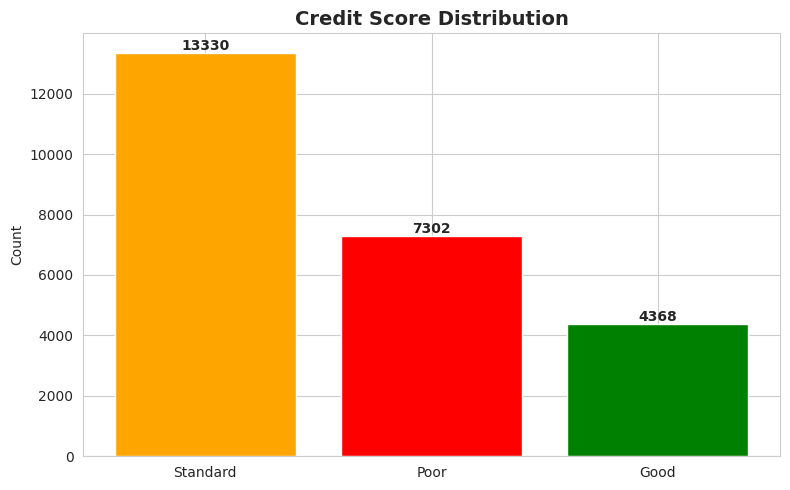

In [10]:
eda_raw = EDAExplorer(df_pre_impute)
eda_raw.plot_target_distribution()

### 5.2 Numeric Distributions

Several key numeric features are **right-skewed** (Annual_Income, Outstanding_Debt), which the skewness check below confirms.

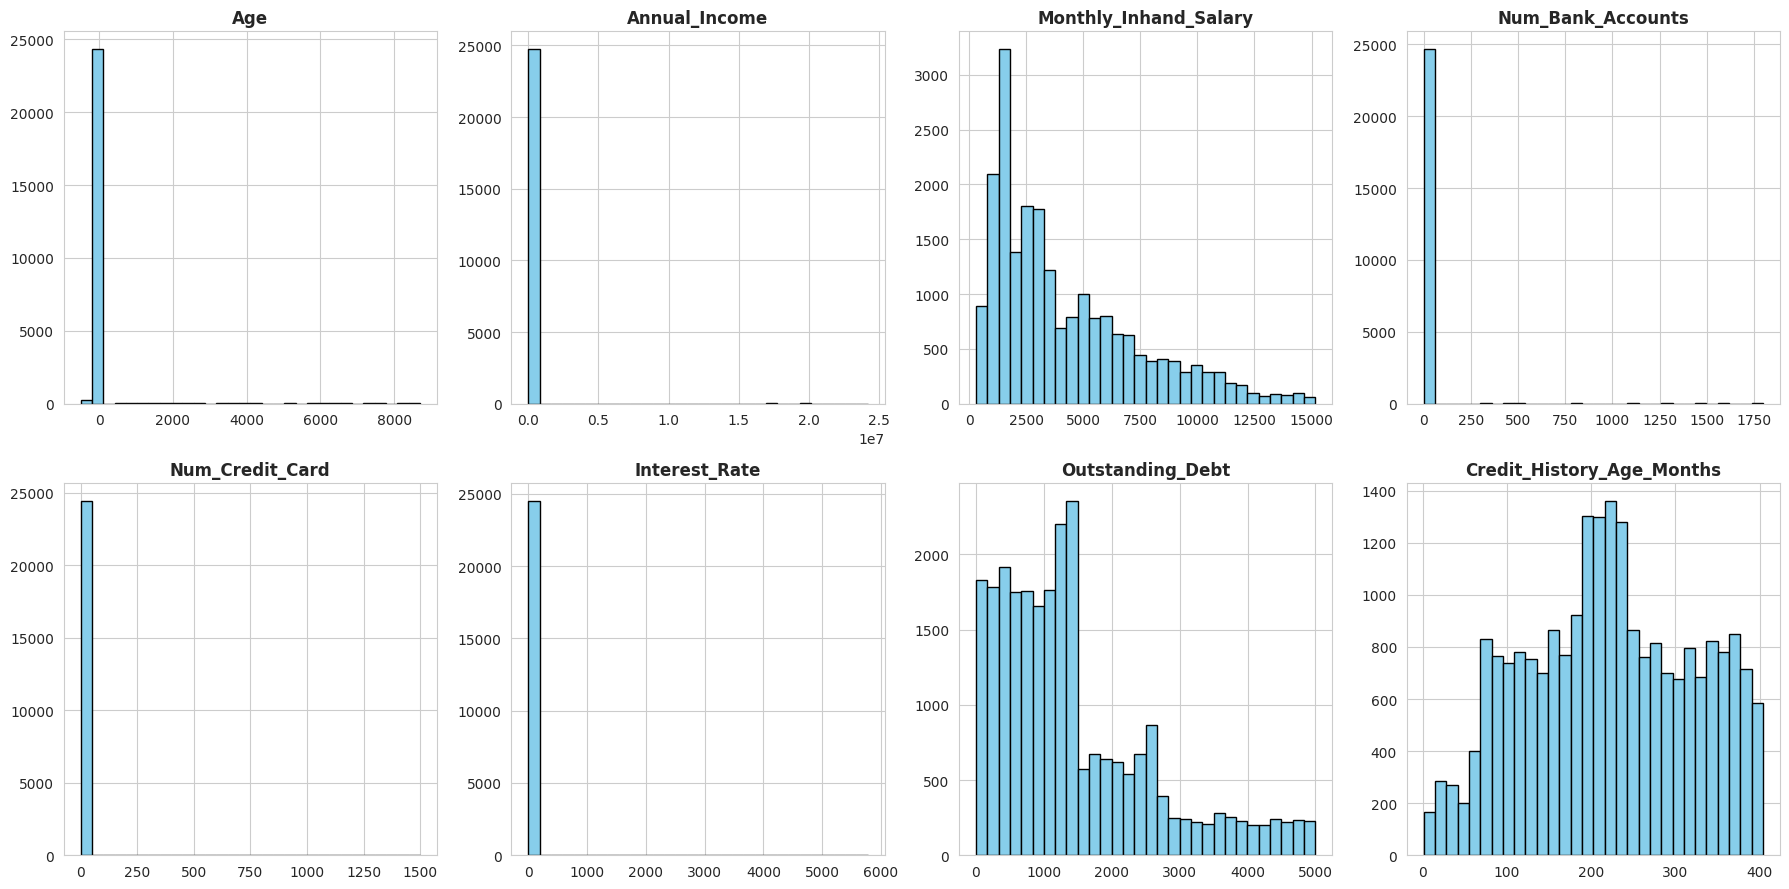

In [11]:
KEY_NUMERIC = [
    'Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
    'Num_Credit_Card', 'Interest_Rate', 'Outstanding_Debt', 'Credit_History_Age_Months'
]
eda_raw.plot_numeric_distributions(KEY_NUMERIC)

### 5.3 Missing Values Heatmap (Before Imputation)

After replacing placeholders with NaN, the real missingness pattern appears.
Columns such as `Credit_History_Age_Months`, `Monthly_Balance` and `Amount_invested_monthly` have gaps.
The gaps are scattered randomly (no blocks), so median/mode imputation is reasonable.

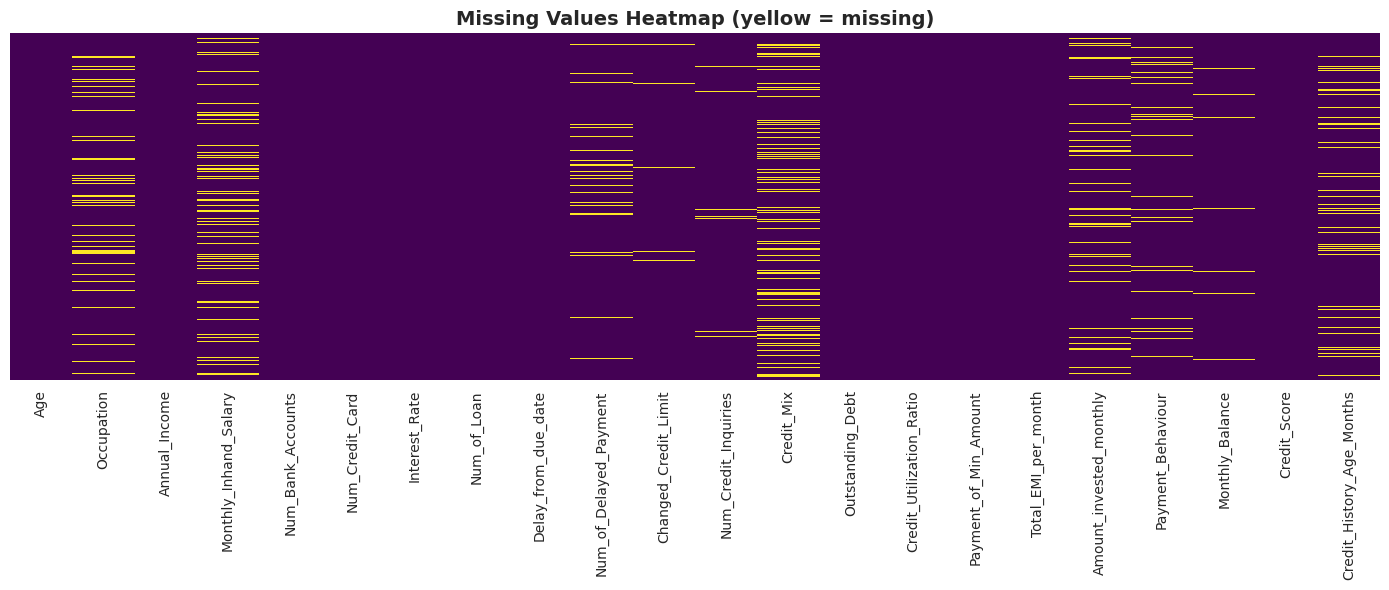

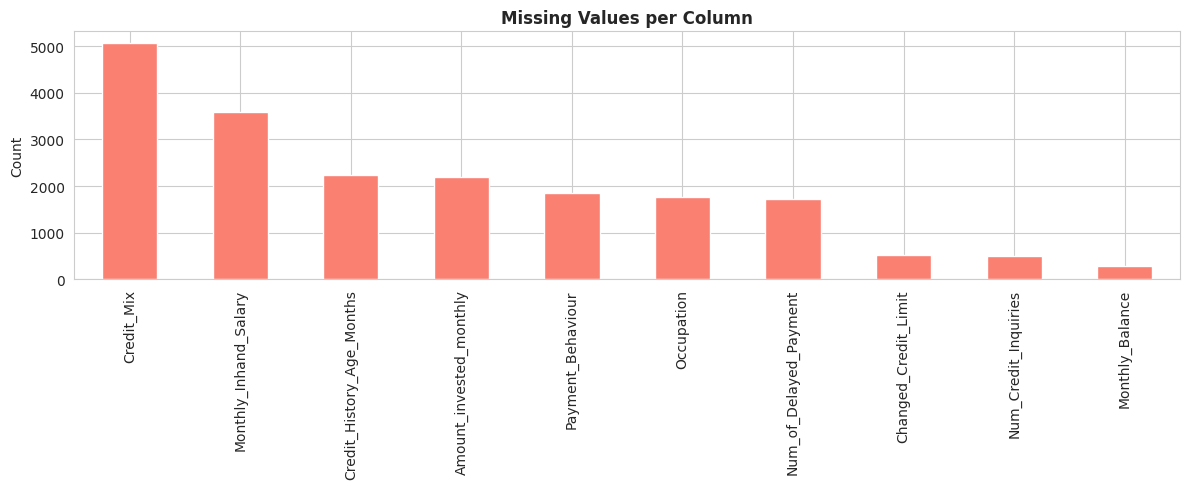

In [12]:
eda_raw.plot_missing_heatmap()

### 5.4 Outlier Detection

`Age` has extreme outliers far above the whiskers. Other features (Annual_Income, Num_Bank_Accounts) also have outliers,
but Age is the one that is clearly impossible from a domain point of view (ages in the thousands), so that is what gets fixed.

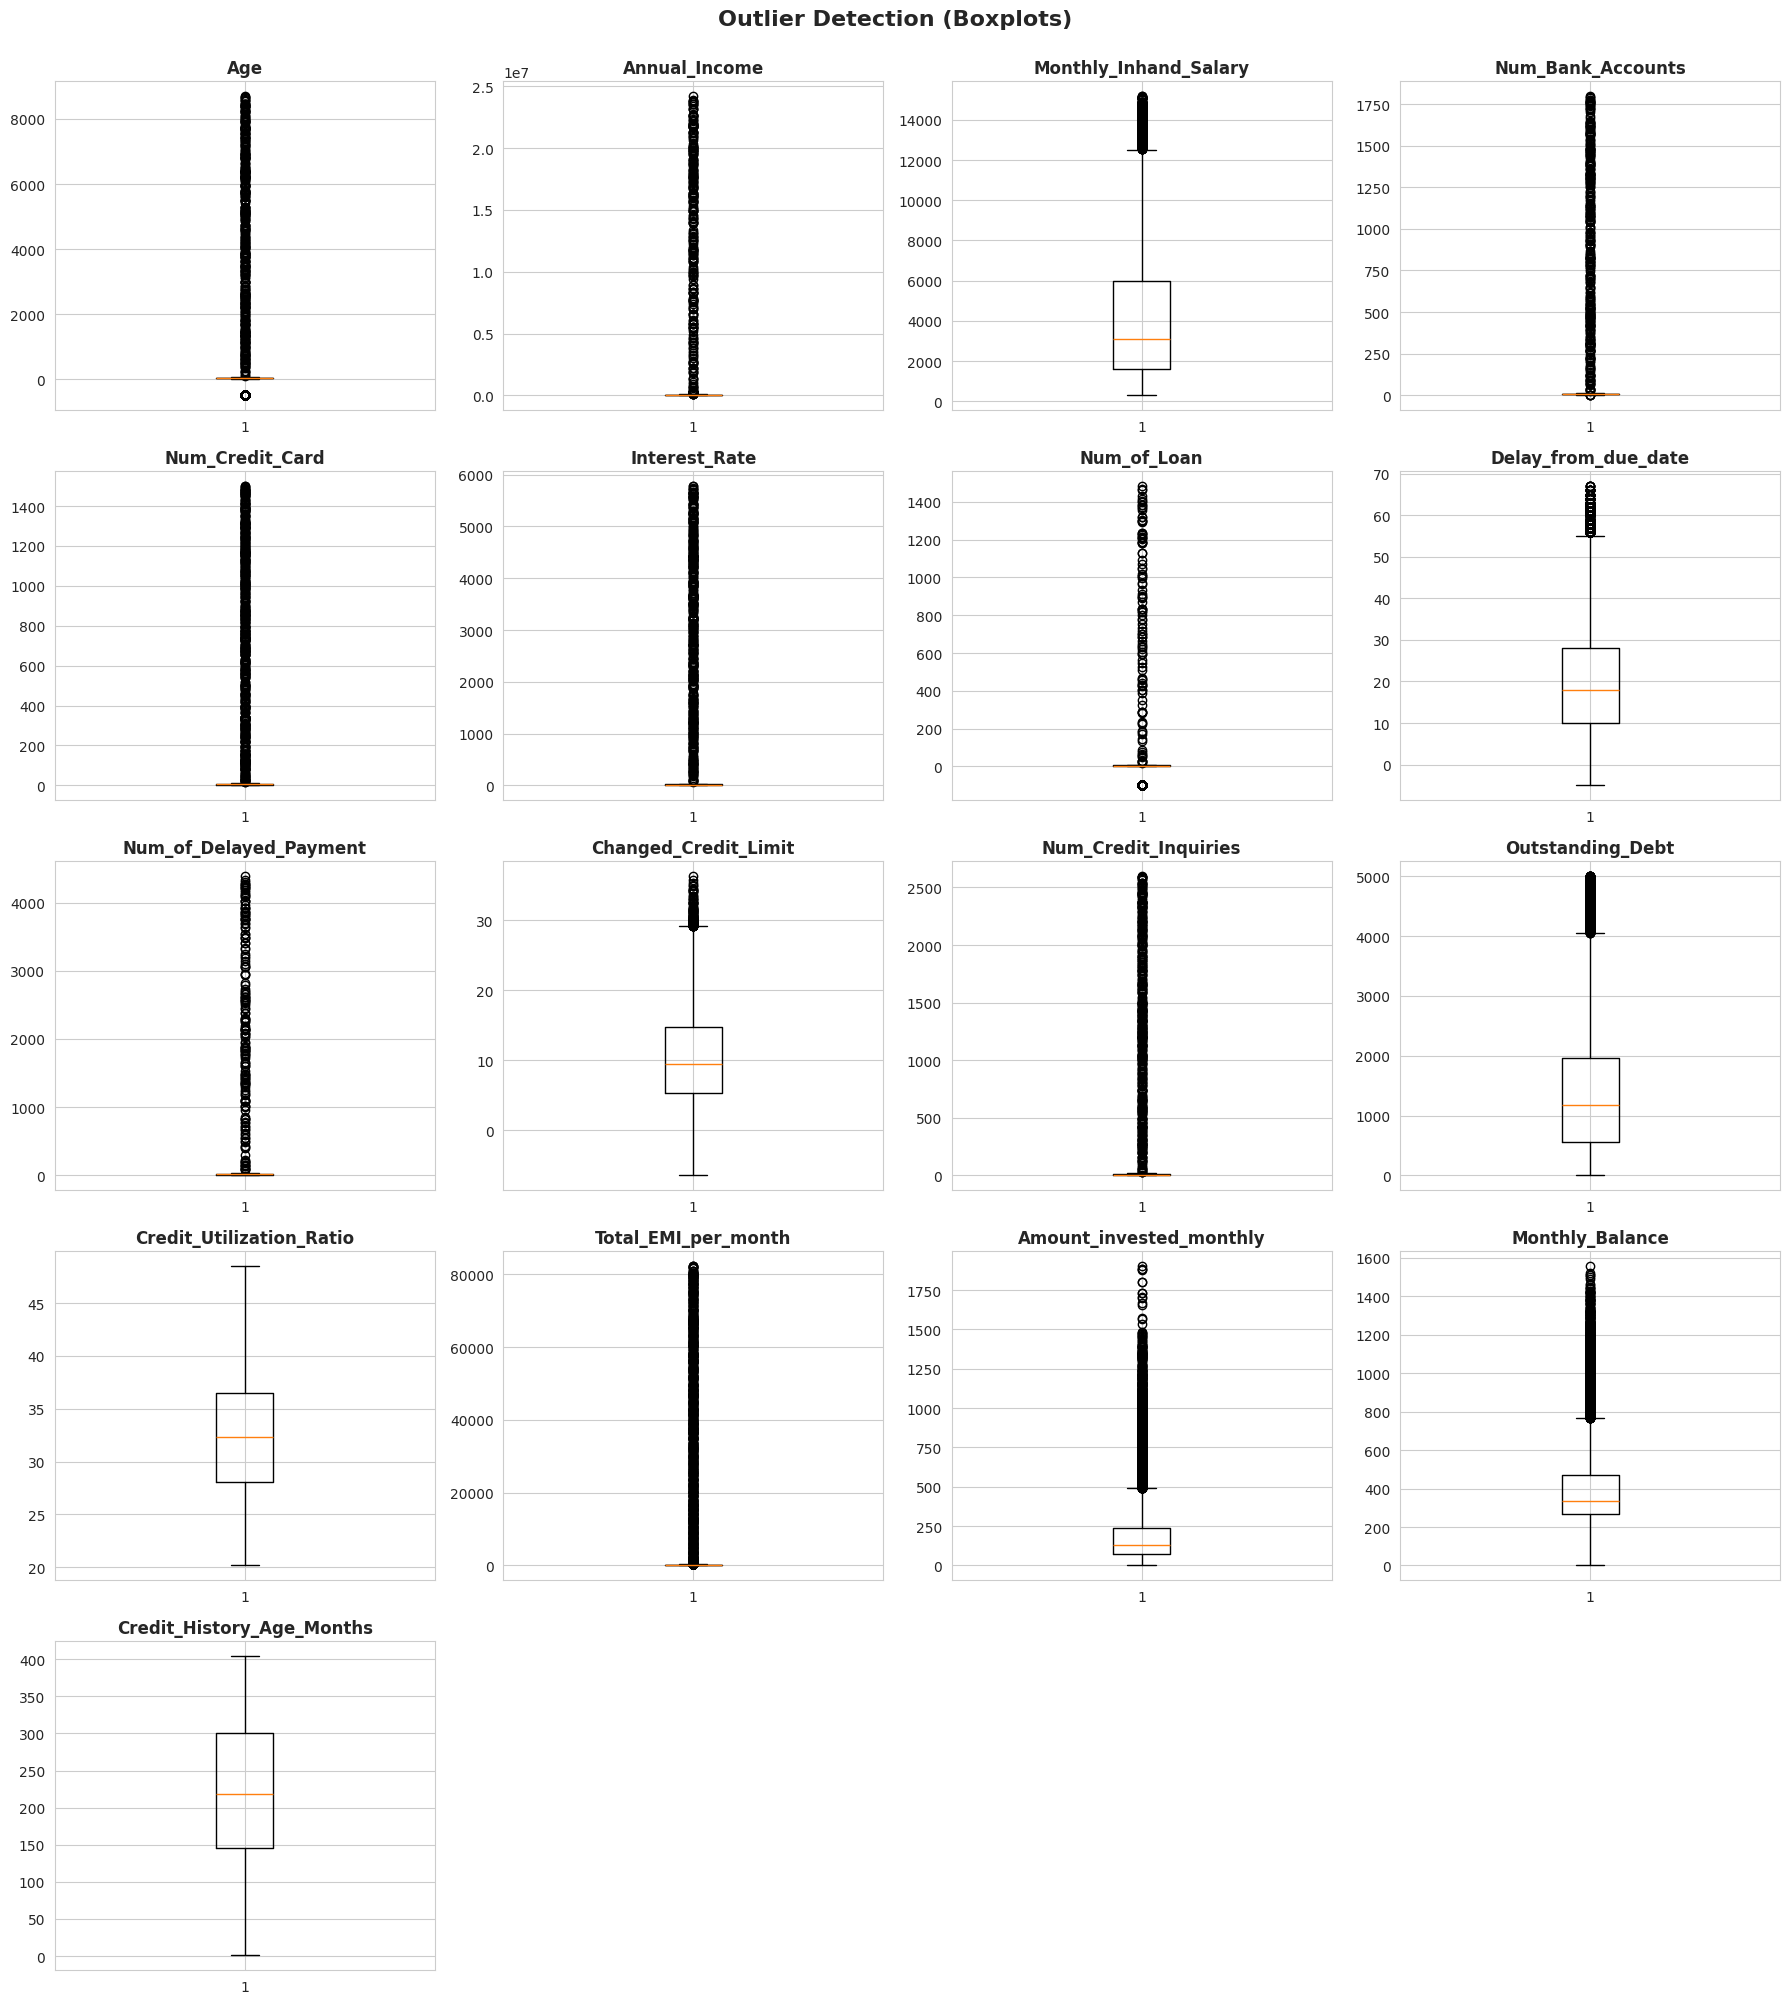

In [13]:
ALL_NUMERIC = df_pre_impute.select_dtypes(include=[np.number]).columns.tolist()
eda_raw.plot_outlier_boxplots(ALL_NUMERIC)

### 5.5 Age: Before vs After Outlier Handling

Why the valid range is set to `[14, 100]`: before cleaning some ages are in the thousands; after cleaning the distribution looks like a normal adult population.

Age outliers handled: 666 rows -> NaN


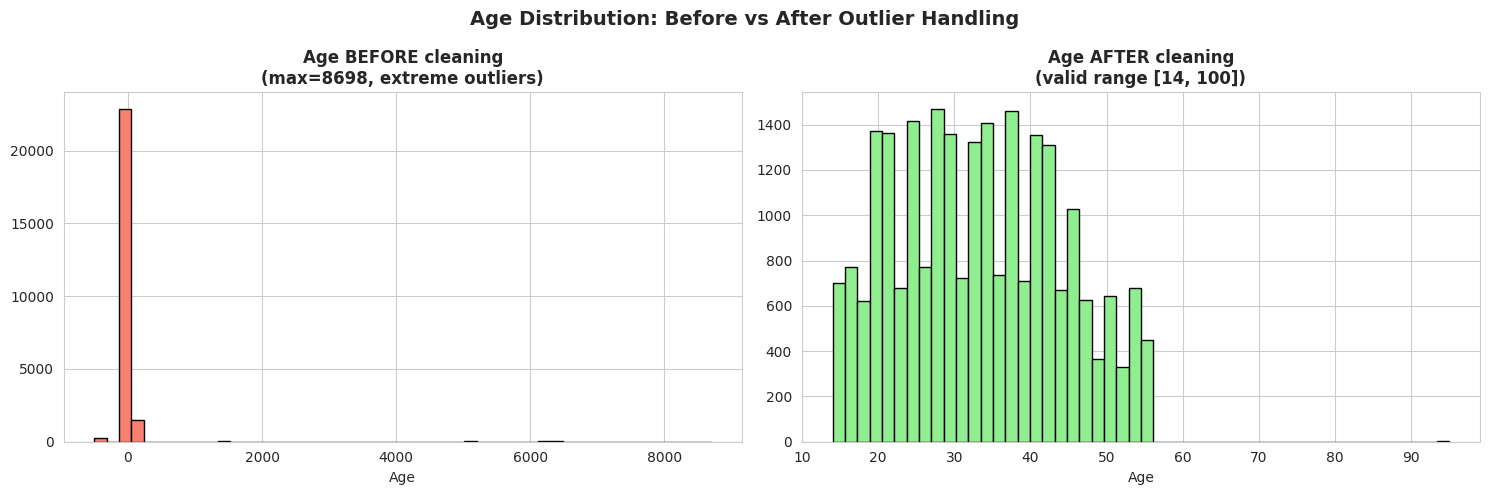

In [14]:
# Run handle_age_outliers to get the before/after snapshot
cleaner_age = DataCleaner(df_raw)
cleaner_age.run_until_placeholders()
cleaner_age.handle_age_outliers()

EDAExplorer.plot_age_before_after(
    age_before=cleaner_age.df_before_age_fix,
    age_after=cleaner_age.df['Age']
)

### 5.6 Skewness Check

High skewness (|skew| > 1) means outliers pull the mean, which is why numeric features are imputed with the **median** rather than the mean. Red bars = highly skewed.

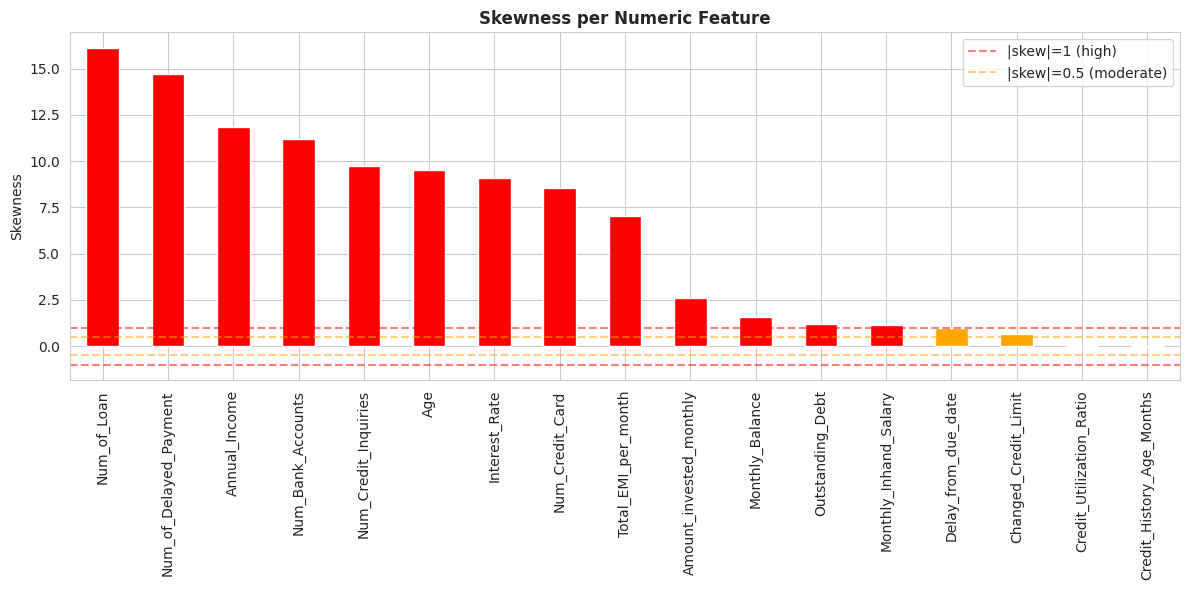


Skewness values:
Num_of_Loan                  16.11
Num_of_Delayed_Payment       14.71
Annual_Income                11.82
Num_Bank_Accounts            11.21
Num_Credit_Inquiries          9.72
Age                           9.51
Interest_Rate                 9.06
Num_Credit_Card               8.56
Total_EMI_per_month           7.05
Amount_invested_monthly       2.60
Monthly_Balance               1.58
Outstanding_Debt              1.20
Monthly_Inhand_Salary         1.11
Delay_from_due_date           0.96
Changed_Credit_Limit          0.64
Credit_Utilization_Ratio      0.02
Credit_History_Age_Months    -0.04
dtype: float64


In [15]:
skew_vals = eda_raw.plot_skewness(ALL_NUMERIC)
print("\nSkewness values:")
print(skew_vals.round(2))

### 5.7 Correlation Matrix

No pair of numeric features is extremely correlated (> 0.9), so there is no severe multicollinearity and all numeric features are kept.

Age outliers handled: 666 rows -> NaN


Duplicates removed: 0 rows


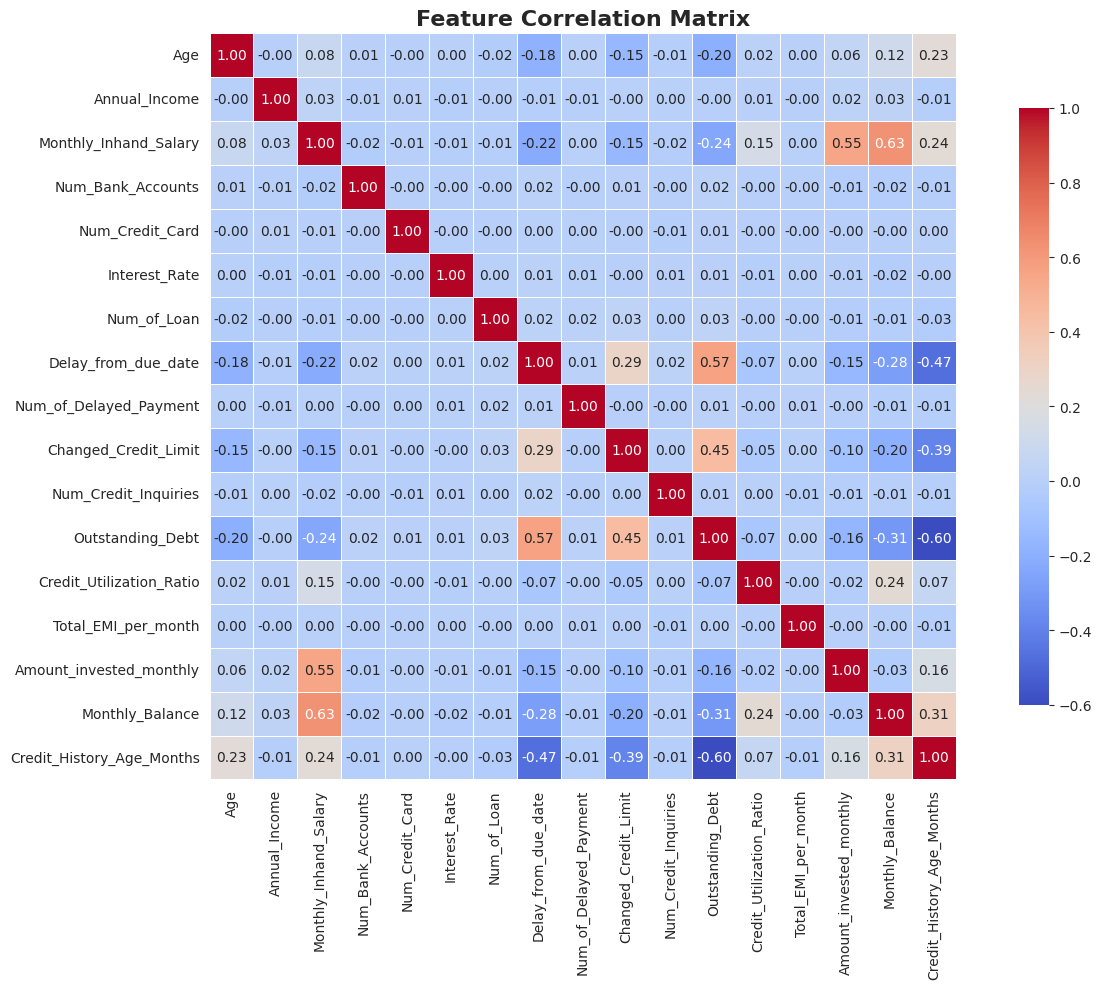

In [16]:
# Use the imputed data so NaNs don't bias the correlations
df_clean = DataCleaner(df_raw).run_all()
eda_clean = EDAExplorer(df_clean.assign(
    Credit_Score=df_clean['Credit_Score']
))
eda_clean.plot_correlation_matrix()

### 5.8 Key Features by Class

`Outstanding_Debt` and `Interest_Rate` tend to be higher for the Poor class — a useful signal for the model.

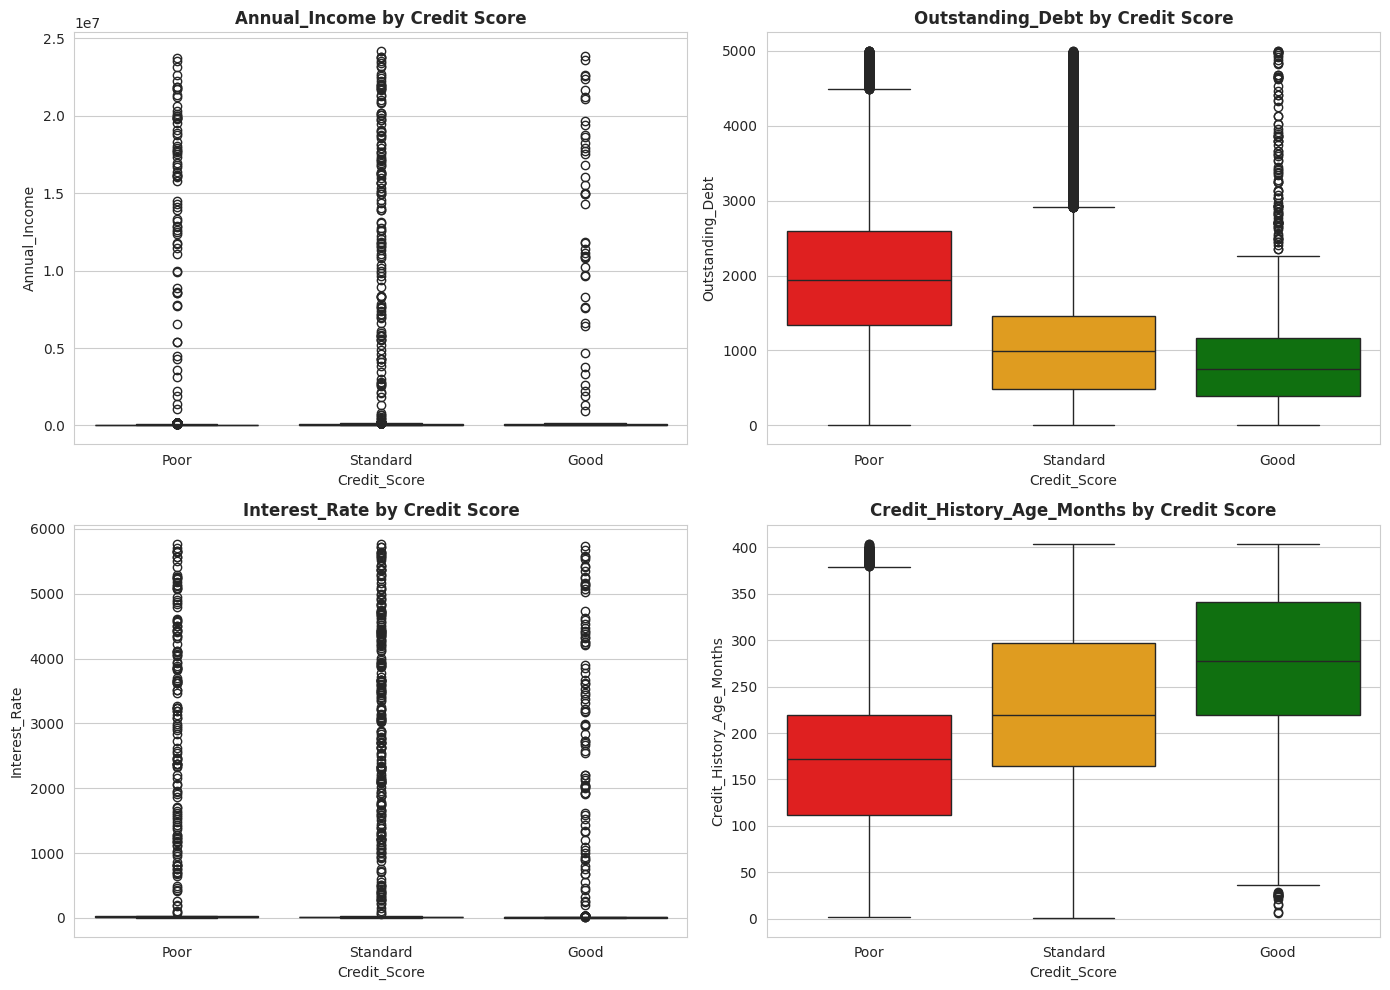

In [17]:
eda_clean.plot_boxplots_by_target([
    'Annual_Income', 'Outstanding_Debt', 'Interest_Rate', 'Credit_History_Age_Months'
])

### 5.9 Pairplot of Key Features

Limited to 5 key features and a 2,000-row sample (all 17 features × 25k rows would be slow and unreadable). Shows how separable the classes are pairwise.

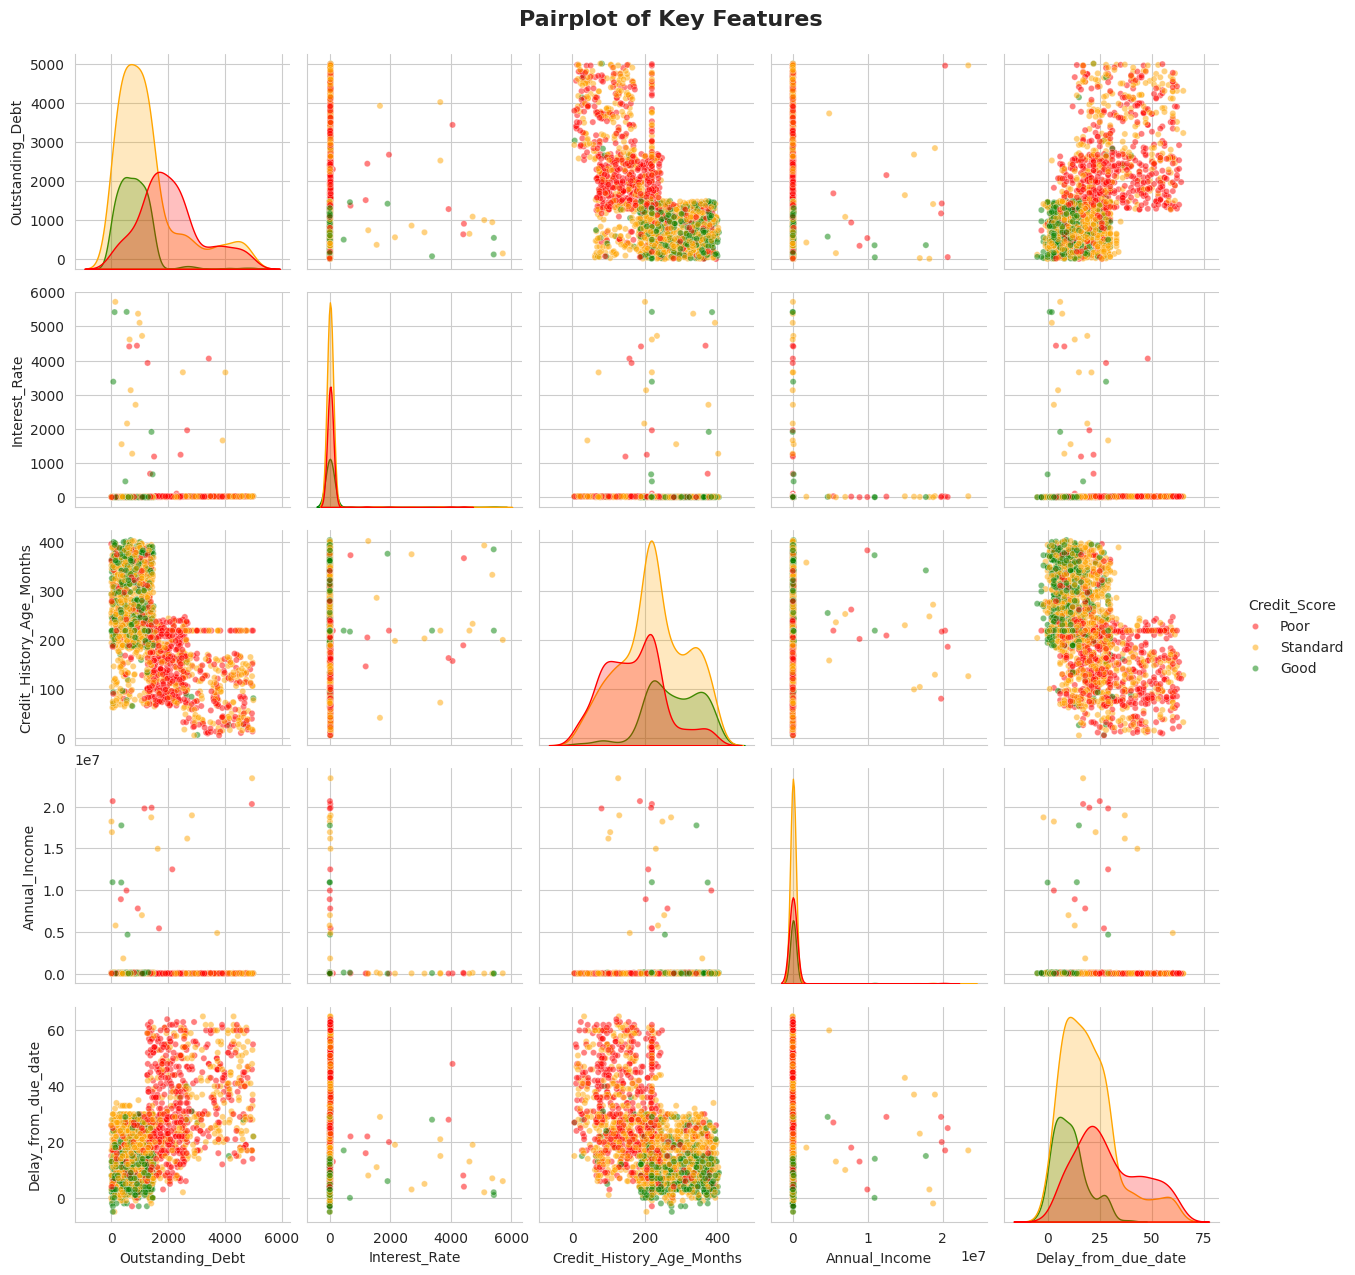

In [18]:
eda_clean.plot_pairplot([
    'Outstanding_Debt', 'Interest_Rate', 'Credit_History_Age_Months',
    'Annual_Income', 'Delay_from_due_date'
])

### 5.10 Categorical Features vs Target

`Credit_Mix` is very informative: most "Bad" mixes end up Poor and most "Good" mixes end up Good.

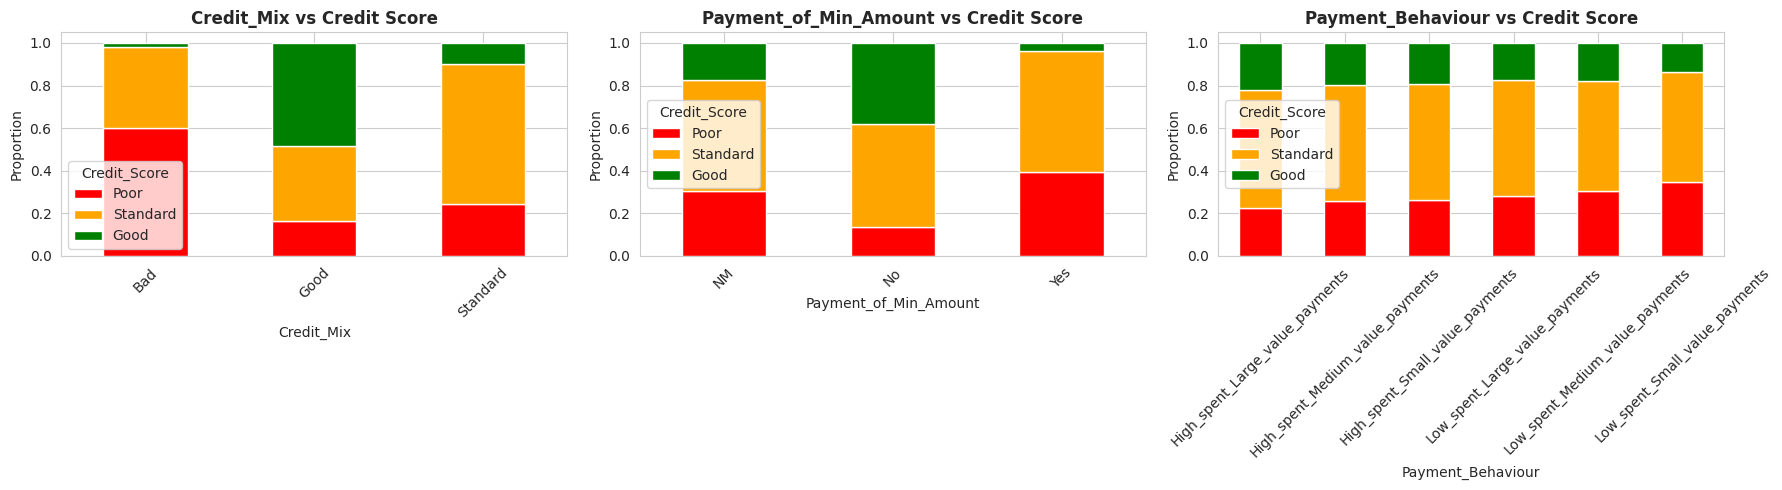

In [19]:
eda_clean.plot_categorical_vs_target(['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour'])

## 6. Save Cleaned Data

The cleaned data is saved to `../pipeline/ingested/data_cleaned.csv` for the modelling notebook.

In [20]:
# ========================================
# 6. SAVE CLEANED DATA
# ========================================
from pathlib import Path

output_path = Path('../pipeline/ingested/data_cleaned.csv')
output_path.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(output_path, index=False)

print(f"Cleaned data saved: {output_path}")
print(f"Shape: {df_clean.shape}")
print(f"Missing values: {df_clean.isnull().sum().sum()}")

Cleaned data saved: ../pipeline/ingested/data_cleaned.csv
Shape: (25000, 22)
Missing values: 0


## Key Findings

1. **Imbalanced target** — Standard ~53%, Poor ~29%, Good ~17% → evaluate with macro-F1.
2. **Very dirty data** — trailing underscores, junk placeholders (`_______`, `_`, `!@9#%8`), durations stored as text.
3. **Impossible ages** (values in the thousands) → valid range [14, 100].
4. **High skewness** in several features (Annual_Income, Outstanding_Debt) → median imputation.
5. **Missing values are scattered randomly** → median/mode imputation is safe.
6. **No severe multicollinearity** → all numeric features kept.
7. **Strongest signals**: `Credit_Mix`, `Outstanding_Debt`, `Interest_Rate`, `Credit_History_Age`.

**Preprocessing decisions backed by the EDA**
- Numeric imputation → median (skewed data)
- Categorical imputation → mode
- Drop identity columns (ID, Customer_ID, Name, SSN) → no predictive value
- Drop Type_of_Loan (free text, high cardinality) and Month (weak signal)